# 08 — Como cada setor do IBGE é ligado a um pronto-atendimento (e onde entra o Dijkstra)

## A pergunta

O IBGE (Censo 2022) nos dá **setores censitários**: pedaços pequenos da cidade com população, área e renda. O CNES nos dá os **pontos** onde estão os PAs do SUS. Não existe um código que ligue um ao outro, então nós construímos essa ligação. Este notebook mostra, passo a passo e com uma figura, como isso é feito.

## O mapeamento, em cinco passos

1. **Ponto do setor.** Cada setor $s$ vira um ponto dentro dele (`representative_point`).
2. **Ponto na rua.** Esse ponto é ligado ao nó mais próximo da rede do OpenStreetMap, com distância $a_s$.
3. **PA na rua.** Cada PA $p$ é ligado ao nó mais próximo, com distância $c_p$.
4. **Dijkstra.** Entre o nó do setor e o nó de cada PA, o algoritmo encontra a menor distância pelas ruas **respeitando as mãos de direção**: $b_{sp}$. Para eficiência, partimos de todos os PAs ao mesmo tempo no grafo com as setas invertidas; assim obtemos o PA mais próximo de cada nó.
5. **Escolha.** Atribuímos ao setor o PA que minimiza $d_s=\min_p(a_s+b_{sp}+c_p)$. A figura mostra essa comparação para um setor real de Fortaleza.

Os setores atribuídos ao mesmo PA formam aqui a **área de atendimento** daquele PA: não é uma delimitação oficial do SUS. É essa área que entra no L2: $A$ é a soma das áreas dos setores, $P$ a soma dos moradores, $m$ o número de PAs e $\rho=P/A$, $D=m/A$.

(Dijkstra não faz parte dos slides do curso; é o método que usamos para medir a distância pela rede, e o resto da análise usa as leis de escala dadas em aula.)

In [1]:
from pathlib import Path
import sys, unicodedata
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import osmnx as ox
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import dijkstra
from shapely.geometry import box, LineString
from IPython.display import display, Markdown

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/"PLANO.md").exists())
sys.path.insert(0, str(RAIZ/"scripts"))
import estilo
estilo.aplicar()
BASE = RAIZ/"dados/processados/retomada/base"
DIST = RAIZ/"dados/processados/retomada/distancias"
FIG = RAIZ/"figuras/metodo"; FIG.mkdir(parents=True, exist_ok=True)

## 2. O caso real: Fortaleza, PAs do SUS (painéis b e c)

Recalculamos Fortaleza com o mesmo procedimento do notebook `retomada/03` (rede recortada 5 km além do município, maior componente fortemente conexa, ligação de cada PA incluída no custo) e **conferimos que reproduz exatamente** as distâncias já salvas.

In [2]:
NOME, UF, COD = "Fortaleza - CE", "CE", "2304400"
unidades = pd.read_csv(BASE/"pa_capitais_corrigido.csv", dtype={"CO_CNES": str})
pa = unidades[(unidades.municipio == NOME) & unidades.atende_sus].reset_index(drop=True)

partes = gpd.read_file(RAIZ/"dados/ibge/setores_gpkg"/f"{UF}_setores_CD2022.gpkg",
                       where=f"CD_MUN='{COD}'", columns=["CD_SETOR", "CD_SIT"])
partes = partes.loc[partes.CD_SIT != "9"].to_crs(4674)
crs = partes.estimate_utm_crs()
partes = partes.to_crs(crs)
limite = partes.geometry.union_all()
geo = partes[["CD_SETOR", "geometry"]].dissolve(by="CD_SETOR", as_index=False)

csv = pd.read_csv(DIST/"fortaleza_drive_sus_setores.csv", dtype={"CD_SETOR": str, "CO_CNES": str})
geo = geo.merge(csv, on="CD_SETOR", how="left", validate="one_to_one")
assert len(geo) == len(csv)

rede = ox.load_graphml(RAIZ/"dados/osm/fortaleza_drive.graphml")
lim = gpd.GeoSeries([limite.buffer(5000)], crs=crs).to_crs(4326).iloc[0]
rede = ox.truncate.truncate_graph_polygon(rede, lim)
rede = ox.truncate.largest_component(rede, strongly=True)
rede = ox.project_graph(rede, to_crs=crs)

nos = list(rede.nodes); indice = {n: i for i, n in enumerate(nos)}
arestas = pd.DataFrame([(indice[v], indice[u], d["length"]) for u, v, d in rede.edges(data=True)],
                       columns=["de", "para", "comprimento"])
arestas = arestas.groupby(["de", "para"], as_index=False).comprimento.min()
arestas["comprimento"] = arestas.comprimento.clip(lower=.01)
n = len(nos)
matriz = coo_matrix((arestas.comprimento, (arestas.de, arestas.para)), shape=(n, n)).tocsr()

pontos = geo.geometry.representative_point()
no_setor, lig_setor = ox.distance.nearest_nodes(rede, pontos.x, pontos.y, return_dist=True)
pa_pts = gpd.GeoDataFrame(pa, geometry=gpd.points_from_xy(pa.lon, pa.lat), crs=4326).to_crs(crs)
pa["no"], pa["lig"] = ox.distance.nearest_nodes(rede, pa_pts.geometry.x, pa_pts.geometry.y, return_dist=True)
pa["x"], pa["y"] = pa_pts.geometry.x.to_numpy(), pa_pts.geometry.y.to_numpy()

aux = np.arange(n, n + len(pa))
orig = matriz.tocoo()
total = coo_matrix((np.r_[orig.data, pa.lig.to_numpy()],
                    (np.r_[orig.row, aux], np.r_[orig.col, [indice[x] for x in pa.no]])),
                   shape=(n + len(pa),) * 2).tocsr()
dist, pred, origem = dijkstra(total, directed=True, indices=aux, min_only=True, return_predecessors=True)
idx_set = np.array([indice[x] for x in no_setor])
d_calc = dist[idx_set] + lig_setor
cnes_calc = pa.CO_CNES.to_numpy()[origem[idx_set] - n]

np.testing.assert_allclose(d_calc, geo.d_m.to_numpy(), rtol=1e-9, atol=1e-6)
print(f"Reproduz as {len(geo)} distâncias salvas. PAs: {len(pa)}. Trocas de PA em empate: {(cnes_calc != geo.CO_CNES.to_numpy()).sum()}")
geo["a_m"], geo["d_calc"] = lig_setor, d_calc

Reproduz as 4407 distâncias salvas. PAs: 12. Trocas de PA em empate: 0


## 3. Um setor de exemplo (painel a)

Para a figura, escolhemos um setor em que **o PA mais perto em linha reta não é o mais perto pelas ruas**: é o caso que mostra por que medimos a distância na rede. Regra (sem escolha manual): setor válido, PA mais próximo pelas ruas entre 1,5 e 3,5 km, segundo PA entre 10% e 50% mais longe, os dois PAs a menos de 3 km um do outro (para caber na ampliação) e, entre esses, o setor em que o segundo PA fica mais perto em linha reta. Calculamos o Dijkstra a partir de cada PA, seguimos os predecessores para desenhar as duas rotas e decompomos cada distância em $a + b + c$. Os números vão para `dados/processados/analises/metodo/exemplo_setor_fortaleza.csv`, lido pelo notebook 07.

In [3]:
valido = (geo.populacao > 0) & (geo.ligacao_m <= 2000) & np.isfinite(geo.d_m)
geo["valido"] = valido
cont = geo[valido].groupby("CO_CNES").size()

# Distância de cada nó até cada PA (grafo com setas invertidas, uma origem por PA), já somando c_p.
dist_pa, pred_pa = [], []
for no_, lig_ in zip(pa.no, pa.lig):
    d_, p_ = dijkstra(matriz, directed=True, indices=indice[no_], return_predecessors=True)
    dist_pa.append(d_ + lig_); pred_pa.append(p_)
dist_pa, pred_pa = np.vstack(dist_pa), np.vstack(pred_pa)
d_setor_pa = dist_pa[:, idx_set] + geo.a_m.to_numpy()          # (PAs, setores): a + b + c
np.testing.assert_allclose(d_setor_pa.min(axis=0), geo.d_m.to_numpy(), rtol=1e-9, atol=1e-6)

pts = geo.geometry.representative_point()
reta = np.hypot(pts.x.to_numpy()[None, :] - pa.x.to_numpy()[:, None], pts.y.to_numpy()[None, :] - pa.y.to_numpy()[:, None])
ordem_pa = np.argsort(d_setor_pa, axis=0)
k = np.arange(len(geo))
p1, p2 = ordem_pa[0], ordem_pa[1]
d1, d2 = d_setor_pa[p1, k], d_setor_pa[p2, k]
e1, e2 = reta[p1, k], reta[p2, k]
sep = np.hypot(pa.x.to_numpy()[p1] - pa.x.to_numpy()[p2], pa.y.to_numpy()[p1] - pa.y.to_numpy()[p2])
# Regra do exemplo: o PA mais perto pelas ruas NÃO é o mais perto em linha reta;
# distâncias moderadas e os dois PAs a menos de 3 km um do outro (para caber na ampliação).
cand = valido.to_numpy() & (np.argmin(reta, axis=0) == p2) & (d1 > 1500) & (d1 < 3500) & (d2/d1 > 1.1) & (d2/d1 < 1.5) & (sep < 3000)
i = int(np.flatnonzero(cand)[np.argmax((e1 - e2)[cand])])
escolhido = geo.iloc[i]

def rota_ate(j):
    """Nós do menor percurso do nó do setor até o nó do PA j (sentido setor → PA)."""
    caminho = [idx_set[i]]
    while caminho[-1] != indice[pa.no.iloc[j]]:
        caminho.append(pred_pa[j, caminho[-1]])
    return [nos[q] for q in caminho]

def linha(u, v):
    d = min(rede[u][v].values(), key=lambda e: e["length"])
    return d.get("geometry") or LineString([(rede.nodes[u]["x"], rede.nodes[u]["y"]), (rede.nodes[v]["x"], rede.nodes[v]["y"])])

exemplo = {}
for rot, j in [("PA1", p1[i]), ("PA2", p2[i])]:
    ids = rota_ate(j)
    c_ = float(pa.lig.iloc[j]); a_ = float(escolhido.a_m)
    b_ = float(d_setor_pa[j, i] - a_ - c_)
    assert abs(sum(min(rede[u][v].values(), key=lambda e: e["length"])["length"] for u, v in zip(ids[:-1], ids[1:])) - b_) < 1
    exemplo[rot] = {"j": int(j), "rota": [linha(u, v) for u, v in zip(ids[:-1], ids[1:])], "a": a_, "b": b_, "c": c_,
                    "d": a_ + b_ + c_, "reta": float(reta[j, i]), "nome": pa.NO_FANTASIA.iloc[j]}
assert exemplo["PA1"]["d"] < exemplo["PA2"]["d"] and exemplo["PA1"]["reta"] > exemplo["PA2"]["reta"]
assert pa.CO_CNES.iloc[exemplo["PA1"]["j"]] == escolhido.CO_CNES
for rot, e in exemplo.items():
    print(f"{rot} ({e['nome']}): a = {e['a']:.0f} m, b = {e['b']:.0f} m, c = {e['c']:.0f} m, d = {e['d']:.0f} m; linha reta {e['reta']:.0f} m")
(RAIZ/"dados/processados/analises/metodo").mkdir(parents=True, exist_ok=True)
pd.DataFrame([{"pa": rot, **{k_: round(v, 1) for k_, v in e.items() if k_ in ("a", "b", "c", "d", "reta")}} for rot, e in exemplo.items()]
             ).to_csv(RAIZ/"dados/processados/analises/metodo/exemplo_setor_fortaleza.csv", index=False)


PA1 (UNIDADE PRONTO ATENDIMENTO JOSE WALTER): a = 23 m, b = 1825 m, c = 50 m, d = 1898 m; linha reta 1654 m
PA2 (UPA UNIDADE PRONTO ATENDIMENTO JANGURUSSU): a = 23 m, b = 2457 m, c = 45 m, d = 2525 m; linha reta 1396 m


## 4. A figura

(a) Ampliação real de Fortaleza: o setor (quadrado preto), sua ligação $a$ ao cruzamento mais próximo e o menor percurso pelas ruas até o PA 1 (azul) e até o PA 2 (laranja), com as contas $a+b+c$. O fundo colorido indica a área de atendimento de cada PA. (b) Fortaleza inteira: cada cor reúne os setores com o mesmo PA mais próximo pelas ruas; linhas brancas são as vias principais.

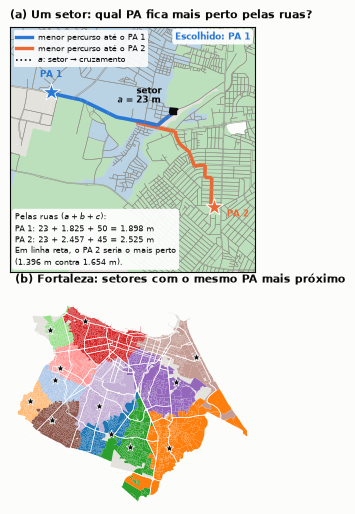

In [4]:
plt.rcParams.update({"font.size": 7.5, "axes.titlesize": 8})
fig, (axa, axb) = plt.subplots(2, 1, figsize=(3.4, 6.2), gridspec_kw={"height_ratios": [1, .82], "hspace": .14})
br = lambda v: f"{v:,.0f}".replace(",", ".")
cats = list(cont.index)
paleta = plt.get_cmap("tab20")(np.arange(20))
ordem = np.random.default_rng(3).permutation(len(cats))
cor = {c: paleta[ordem[q] % 20] for q, c in enumerate(cats)}
cor_rota = {"PA1": estilo.AZUL, "PA2": estilo.LARANJA}

ed_all = ox.graph_to_gdfs(rede, nodes=False)
def classe(h):
    h = h[0] if isinstance(h, list) else h
    if h in ("motorway", "trunk", "primary", "motorway_link", "trunk_link", "primary_link"): return 0
    if h in ("secondary", "tertiary", "secondary_link", "tertiary_link"): return 1
    return 2
ed_all["classe"] = ed_all.highway.map(classe)

# janela da ampliação: setor e os dois PAs, com folga
xs = [pts.iloc[i].x] + [pa.x.iloc[e["j"]] for e in exemplo.values()]
ys = [pts.iloc[i].y] + [pa.y.iloc[e["j"]] for e in exemplo.values()]
cx, cy = (min(xs) + max(xs))/2, (min(ys) + max(ys))/2
meia = max(max(xs) - min(xs), max(ys) - min(ys))/2 + 550
jan = (cx - meia, cy - meia, cx + meia, cy + meia)

# (a) ampliação: o cálculo de um setor real
dentro = geo.cx[jan[0]:jan[2], jan[1]:jan[3]]
dentro[~dentro.valido].plot(ax=axa, color=estilo.NEUTRO, lw=0)
dentro[dentro.valido].plot(ax=axa, color=[cor[c] for c in dentro.loc[dentro.valido, "CO_CNES"]], alpha=.30, lw=0)
ed_all.cx[jan[0]:jan[2], jan[1]:jan[3]].plot(ax=axa, color="#8f8d86", linewidth=.35)
for rot in ("PA2", "PA1"):
    gpd.GeoSeries(exemplo[rot]["rota"], crs=crs).plot(ax=axa, color=cor_rota[rot], linewidth=2.6, zorder=3)
gpd.GeoSeries([escolhido.geometry], crs=crs).boundary.plot(ax=axa, color=estilo.TEXTO, linewidth=1.1, zorder=4)
px, py = pts.iloc[i].x, pts.iloc[i].y
no_s = rede.nodes[nos[idx_set[i]]]
axa.plot([px, no_s["x"]], [py, no_s["y"]], ls=":", color=estilo.TEXTO, lw=1.3, zorder=5)
axa.scatter(px, py, marker="s", s=22, color=estilo.TEXTO, zorder=6)
axa.annotate(f"setor\n$a$ = {br(escolhido.a_m)} m", (px, py), xytext=(-8, 6), textcoords="offset points", ha="right", fontsize=6.3, fontweight="bold", linespacing=1.1)
for rot, e in exemplo.items():
    x_, y_ = pa.x.iloc[e["j"]], pa.y.iloc[e["j"]]
    axa.scatter(x_, y_, marker="*", s=170, color=cor_rota[rot], edgecolor="white", lw=.7, zorder=6)
    dx, dy, ha_, va_ = ((0, 9, "center", "bottom") if rot == "PA1" else (9, -2, "left", "top"))
    axa.annotate(f"PA {rot[-1]}", (x_, y_), xytext=(dx, dy), textcoords="offset points", ha=ha_, va=va_, fontsize=6.8,
                 fontweight="bold", color=cor_rota[rot])
e1_, e2_ = exemplo["PA1"], exemplo["PA2"]
conta = (f"Pelas ruas ($a + b + c$):\n"
         f"PA 1: {br(e1_['a'])} + {br(e1_['b'])} + {br(e1_['c'])} = {br(e1_['d'])} m\n"
         f"PA 2: {br(e2_['a'])} + {br(e2_['b'])} + {br(e2_['c'])} = {br(e2_['d'])} m\n"
         f"Em linha reta, o PA 2 seria o mais perto\n({br(e2_['reta'])} m contra {br(e1_['reta'])} m).")
axa.text(.02, .02, conta, transform=axa.transAxes, fontsize=6.1, va="bottom", ha="left", linespacing=1.3,
         bbox=dict(boxstyle="round,pad=.35", fc="white", ec="none", alpha=.92), zorder=7)
axa.text(.98, .98, "Escolhido: PA 1", transform=axa.transAxes, fontsize=6.6, fontweight="bold", color=estilo.AZUL,
         va="top", ha="right", bbox=dict(boxstyle="round,pad=.3", fc="white", ec="none", alpha=.92), zorder=7)
axa.set(xlim=(jan[0], jan[2]), ylim=(jan[1], jan[3]), aspect="equal", xticks=[], yticks=[])
for sp_ in axa.spines.values(): sp_.set_visible(True); sp_.set_color(estilo.TEXTO); sp_.set_linewidth(.8)
axa.set_anchor("N")
axa.legend(handles=[Line2D([], [], color=estilo.AZUL, lw=2.4, label="menor percurso até o PA 1"),
                    Line2D([], [], color=estilo.LARANJA, lw=2.4, label="menor percurso até o PA 2"),
                    Line2D([], [], color=estilo.TEXTO, lw=1.2, ls=":", label="$a$: setor → cruzamento")],
           loc="upper left", fontsize=5.6, frameon=True, framealpha=.92, edgecolor="none", borderpad=.3, labelspacing=.3)

# (b) a mesma regra em toda a cidade
geo[~valido].plot(ax=axb, color=estilo.NEUTRO, lw=0)
geo[valido].plot(ax=axb, color=[cor[c] for c in geo.loc[valido, "CO_CNES"]], lw=0)
ed_all[ed_all.classe == 0].plot(ax=axb, color="white", linewidth=.45, alpha=.9)
axb.scatter(pa.x, pa.y, marker="*", s=42, color=estilo.TEXTO, edgecolor="white", lw=.5, zorder=4)
axb.set_anchor("N")
x0, y0, x1, y1 = geo.total_bounds
axb.set(xlim=(x0 - 300, x1 + 300), ylim=(y0 - 300, y1 + 300), aspect="equal")
axb.axis("off")
axa.set_title("(a) Um setor: qual PA fica mais perto pelas ruas?", loc="left", fontsize=7.6, fontweight="bold")
axb.set_title("(b) Fortaleza: setores com o mesmo PA mais próximo", loc="left", fontsize=7.6, fontweight="bold")
fig.savefig(FIG/"metodo_setor_pa.pdf", bbox_inches="tight")
fig.savefig(FIG/"metodo_setor_pa.png", dpi=220, bbox_inches="tight")
plt.show()
plt.rcParams.update({"font.size": 9.5, "axes.titlesize": 11})


## 5. O que a figura mostra

- Em (a), o PA 2 está mais perto em linha reta, mas pelas ruas o percurso até o PA 1 é menor; o setor é atribuído ao PA 1. Isso só aparece quando a distância é medida pela rede.
- Em (b), a mesma regra aplicada a todos os setores forma as áreas de atendimento usadas no L2. Setores em cinza não têm moradores ou foram excluídos pela regra de ligação/rota.